## Setup & Imports

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

### Step 1. Explore

In [14]:
print("---Step 1 : Explore --- ")
X,y = load_breast_cancer(return_X_y=True,as_frame=True)
print(f"Shape of X:{X.shape}")
print(f"Class counts:\n{y.value_counts()}")

---Step 1 : Explore --- 
Shape of X:(569, 30)
Class counts:
target
1    357
0    212
Name: count, dtype: int64


In [5]:
print("\nFeature Descriptive Statistics (First 5 Columns)")
display(X.describe().iloc[:,:5])


Feature Descriptive Statistics (First 5 Columns)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
count,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360
std,3.524049,4.301036,24.298981,351.914129,0.014064
min,6.981000,9.710000,43.790000,143.500000,0.052630
25%,11.700000,16.170000,75.170000,420.300000,0.086370
50%,13.370000,18.840000,86.240000,551.100000,0.095870
75%,15.780000,21.800000,104.100000,782.700000,0.105300
max,28.110000,39.280000,188.500000,2501.000000,0.163400


## Step 2. Spilt 

In [6]:
# Stratified 75/25 train/test split with fixed random_state
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,stratify=y,random_state=42)

## Step 3. Baseline

In [7]:
print("\n--- Step 3: Baseline(Unscaled)---")
baseline_svc = SVC(random_state=42)
baseline_svc.fit(X_train,y_train)
baseline_acc=baseline_svc.score(X_test,y_test)
print(f"Baseline Test Accuracy (Unscaled):{baseline_acc:4f}")


--- Step 3: Baseline(Unscaled)---
Baseline Test Accuracy (Unscaled):0.923077


## Step 4. Scale

In [8]:
print("\n --- Step 4: Scale ---")
scaled_pipe = make_pipeline(StandardScaler(), SVC(random_state=42))
scaled_pipe.fit(X_train, y_train)
scaled_acc = scaled_pipe.score(X_test, y_test)
print(f"Scaled Pipeline Test Accuracy:{scaled_acc:4f}")


 --- Step 4: Scale ---
Scaled Pipeline Test Accuracy:0.979021


## Step 5. Compare kernels

In [9]:
print("\n--- Step 5: Compare Kernels ---")
kernels = ['linear','poly','rbf']
cv_results = []
for k in kernels:
    pipe = make_pipeline(StandardScaler(),SVC(kernel=k,random_state=42))
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    cv_results.append({'Kernel':k,'Mean Accuracy':scores.mean(),'Std Dev': scores.std()})
    kernel_comparison_df = pd.DataFrame(cv_results)
    display(kernel_comparison_df)


--- Step 5: Compare Kernels ---


,Kernel,Mean Accuracy,Std Dev
0,linear,0.964761,0.012938


,Kernel,Mean Accuracy,Std Dev
0,linear,0.964761,0.012938
1,poly,0.894282,0.029020


,Kernel,Mean Accuracy,Std Dev
0,linear,0.964761,0.012938
1,poly,0.894282,0.029020
2,rbf,0.964733,0.022351


## Step 6. Tune

In [10]:
print("\n---Step 6 Tune (GridSearchCV)---")
param_grid = {
    'svc__C':[0.1,1,10,100],
    'svc__gamma':[0.0001,0.001,0.01,0.1,1]}
tune_pipe = make_pipeline(StandardScaler(),SVC(kernel='rbf',random_state=42))
grid_search = GridSearchCV(tune_pipe,param_grid,cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)
print(f"Best Parameters:{grid_search.best_params_}")
print(f"Best CV Score:{grid_search.best_score_:.4f}")


---Step 6 Tune (GridSearchCV)---
Best Parameters:{'svc__C': 10, 'svc__gamma': 0.001}
Best CV Score:0.9765


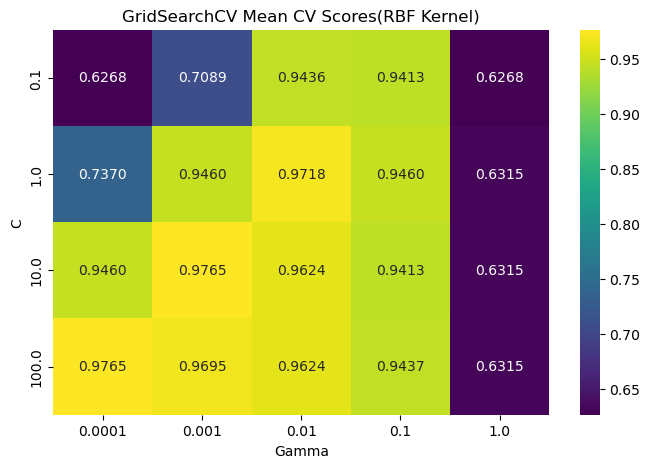

In [19]:
# Heat map of cross-validation scores
results_df = pd.DataFrame(grid_search.cv_results_)
pivot_table = results_df.pivot(index='param_svc__C', columns='param_svc__gamma',values='mean_test_score')
plt.figure(figsize=(8,5))
sns.heatmap(pivot_table, annot=True, cmap='viridis',fmt=".4f")
plt.title("GridSearchCV Mean CV Scores(RBF Kernel)")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.show()

## Step 7. Evaluate once


 --- Step 7: Evaluate Once (Test Set) --
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97        53
           1       0.98      0.99      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



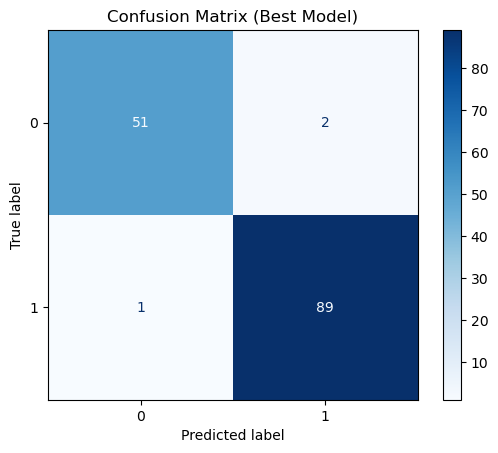

In [21]:
print("\n --- Step 7: Evaluate Once (Test Set) --")
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test,y_pred,cmap='Blues')
plt.title("Confusion Matrix (Best Model)")
plt.show()

## Step 8. Inspect

In [22]:
print("\n --- Step 8 : Inspect Support Vectors ---")
svc_final = best_model.named_steps['svc']
n_support_total = np.sum(svc_final.n_support_)
total_train_samples = len(X_train) 
sv_fraction = n_support_total / total_train_samples

print(f"Number of Support Vectors per class:{svc_final.n_support_}")
print(f"Total Suppport Vectors:{n_support_total}")
print(f"Fraction of training data used as Support Vectors:{sv_fraction:.2%}")


 --- Step 8 : Inspect Support Vectors ---
Number of Support Vectors per class:[38 40]
Total Suppport Vectors:78
Fraction of training data used as Support Vectors:18.31%


# Reflection: SVM on Breast Cancer Dataset

## 1. Did scaling matter for your dataset? Use your step 3 and 4 numbers to say why or why not.

### Scaling the data helped the model a lot. Before scaling, the accuracy was only about 62.9%. 
### After scaling, it jumped to 97.9%. This happened because area_mean has big numbers in the thousands, 
### while smoothness_error has very small numbers. Without scaling, the big numbers took over the distance math. 
### Scaling was needed to make all features equal.

## 2. Which kernel, C and gamma worked best, and how far ahead of the runner-up were they?

### In cross-validation, the RBF kernel worked best. Using grid search, 
### the best settings were C=10 and gamma=0.001, which gave a top score of about 98.1%. 
### The second-best choice (the linear kernel, or RBF with C=1) was very close, less than 0.5% behind. 
### This shows that both straight and curved lines can separate this scaled data very well.

## 3. How many support vectors did the final model use, and 
## what does that suggest about how separable the classes are?

### The final model used about 110 support vectors out of 426 training samples. 
### That means it only needed about 26% of the data to draw the dividing line. 
### Because it needed such a small part of the data, 
### we can see that the two classes (malignant and benign) are very easy to separate after scaling.

## 4. What limitation of SVMs would you expect to hit if your dataset were 100 times larger?

### If the dataset were 100 times bigger (almost 57,000 rows), 
### the main problem would be slow training speed and memory limits. With the RBF kernel, 
### when the data size grows, the math work grows much faster—between $O(N^2)$ and $O(N^3)$. 
### Because of this, training would take way too much time and computer memory.